<a href="https://colab.research.google.com/github/pauloricardopg/RedesNeuraisArtificiais-PPCOM/blob/main/Forecasting.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Forecasting — Metro Interstate Traffic Volume

## Sobre a base de dados
A base **Metro Interstate Traffic Volume** (UCI Machine Learning Repository) reúne 40.574 registros horários do volume de tráfego na rodovia interestadual I-94 (entre Minneapolis e St. Paul, EUA) entre 2012 e 2018. Além da variável alvo (`traffic_volume`, em veículos/hora), o conjunto inclui variáveis climáticas (`temp`, `rain_1h`, `snow_1h`, `clouds_all`), indicador de feriados (`is_holiday`) e features cíclicas de hora do dia e dia da semana (`hour_sin`, `hour_cos`, `dow_sin`, `dow_cos`) para capturar a forte sazonalidade diária e semanal do trânsito.

## Justificativa dos parâmetros do dataset
* **`sampling_rate = 1`**: Como os dados já possuem frequência horária (1 registro por hora), manter o valor em `1` preserva a resolução original sem descartar observações.
* **`sequence_length = 168`**: Corresponde a uma janela histórica de **7 dias completos (168 horas)**, permitindo que os modelos capturem tanto o ciclo diário (horários de pico) quanto o ciclo semanal (diferença entre dias úteis e fins de semana).
* **`delay = sampling_rate * (sequence_length + 24 - 1)`**: Define o horizonte de previsão para **24 horas à frente** do último instante da janela de entrada, mantendo o mesmo objetivo de previsão de 1 dia trabalhado em aula.
* **`batch_size = 256`**: Mantido no padrão da aula para equilibrar estabilidade do gradiente e tempo de treinamento em GPU.

In [1]:
!wget -q https://archive.ics.uci.edu/ml/machine-learning-databases/00492/Metro_Interstate_Traffic_Volume.csv.gz
!gunzip -f Metro_Interstate_Traffic_Volume.csv.gz

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tensorflow import keras
from tensorflow.keras import layers

# Carregamento e ordenação temporal
df = pd.read_csv('Metro_Interstate_Traffic_Volume.csv')
df['date_time'] = pd.to_datetime(df['date_time'])
df = df.sort_values('date_time')

# Remove timestamps duplicados (causados por múltiplas descrições climáticas na mesma hora)
df = df.drop_duplicates(subset=['date_time'], keep='first').reset_index(drop=True)

# Remove outlier extremo de erro de sensor em rain_1h (registro de 9831 mm)
df = df[df['rain_1h'] < 100].reset_index(drop=True)

# Transforma 'holiday' em variável binária (0 = dia normal, 1 = feriado)
df['is_holiday'] = (df['holiday'].notna() & (df['holiday'] != 'None')).astype(float)

df['hour_sin'] = np.sin(2 * np.pi * df['date_time'].dt.hour / 24.0)
df['hour_cos'] = np.cos(2 * np.pi * df['date_time'].dt.hour / 24.0)
df['dow_sin']  = np.sin(2 * np.pi * df['date_time'].dt.dayofweek / 7.0)
df['dow_cos']  = np.cos(2 * np.pi * df['date_time'].dt.dayofweek / 7.0)

features = [
    'traffic_volume', 'temp', 'rain_1h', 'snow_1h', 'clouds_all', 'is_holiday',
    'hour_sin', 'hour_cos', 'dow_sin', 'dow_cos'
]
df_clean = df[features].copy()

print(f"Total de amostras (horas): {len(df_clean)}")
print(f"Total de dias: {len(df_clean)/24:.1f}")
df_clean.head()

Total de amostras (horas): 40574
Total de dias: 1690.6


,traffic_volume,temp,rain_1h,snow_1h,clouds_all,is_holiday,hour_sin,hour_cos,dow_sin,dow_cos
0,5545,288.28,0.0,0.0,40,0.0,7.071068e-01,-0.707107,0.781831,0.62349
1,4516,289.36,0.0,0.0,75,0.0,5.000000e-01,-0.866025,0.781831,0.62349
2,4767,289.58,0.0,0.0,90,0.0,2.588190e-01,-0.965926,0.781831,0.62349
3,5026,290.13,0.0,0.0,90,0.0,1.224647e-16,-1.000000,0.781831,0.62349
4,4918,291.14,0.0,0.0,75,0.0,-2.588190e-01,-0.965926,0.781831,0.62349


traffic = df_clean['traffic_volume'].values
raw_data = df_clean.values.astype('float32')

# Plotando 14 dias (2 semanas) para visualizar os ciclos diários e de fim de semana
two_weeks = 24 * 14
plt.figure(figsize=(12, 4))
plt.plot(range(two_weeks), traffic[:two_weeks])
plt.title("Volume de Tráfego - Primeiros 14 dias")
plt.xlabel("Horas")
plt.ylabel("Veículos / hora")
plt.show()

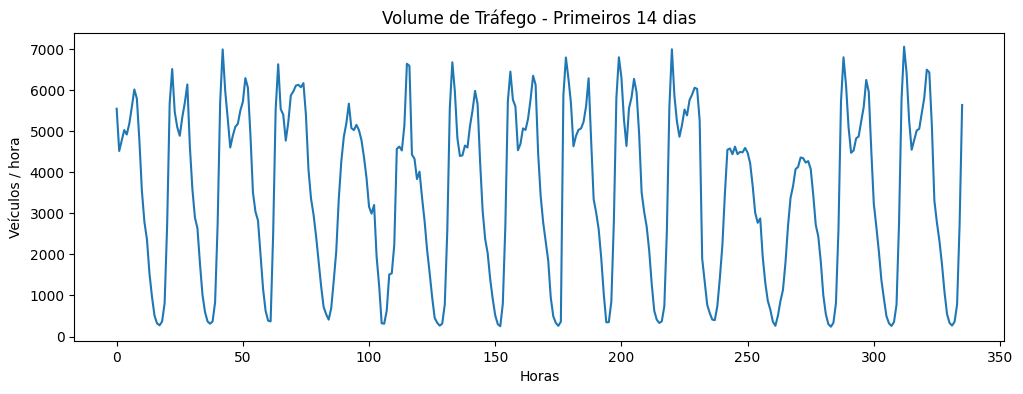

In [2]:
traffic = df_clean['traffic_volume'].values
raw_data = df_clean.values.astype('float32')
traffic = df_clean['traffic_volume'].values.astype('float32')

# Plotando 14 dias (2 semanas) para visualizar os ciclos diários e de fim de semana
two_weeks = 24 * 14
plt.figure(figsize=(12, 4))
plt.plot(range(two_weeks), traffic[:two_weeks])
plt.title("Volume de Tráfego - Primeiros 14 dias")
plt.xlabel("Horas")
plt.ylabel("Veículos / hora")
plt.show()

In [3]:
n_samples = len(raw_data)
num_train_samples = int(0.5 * n_samples)
num_val_samples = int(0.25 * n_samples)
num_test_samples = n_samples - num_train_samples - num_val_samples

print(f"Train: {num_train_samples} | Val: {num_val_samples} | Test: {num_test_samples}")

# Normalização usando APENAS média e desvio padrão do conjunto de treino (evita data leakage)
mean = raw_data[:num_train_samples].mean(axis=0)
raw_data -= mean
std = raw_data[:num_train_samples].std(axis=0)
raw_data /= std

print(f"Média do tráfego (treino): {mean[0]:.2f} | Desvio padrão: {std[0]:.2f}")

Train: 20287 | Val: 10143 | Test: 10144
Média do tráfego (treino): 3281.45 | Desvio padrão: 2012.41


In [4]:
sampling_rate = 1
sequence_length = 168  # 7 dias (168 horas)
delay = sampling_rate * (sequence_length + 24 - 1)  # Previsão para 24h à frente
batch_size = 256
num_features = raw_data.shape[-1]

train_dataset = keras.utils.timeseries_dataset_from_array(
    raw_data[:-delay],
    targets=raw_data[delay:, 0],  # Alvo normalizado
    sampling_rate=sampling_rate,
    sequence_length=sequence_length,
    shuffle=True,
    batch_size=batch_size,
    start_index=0,
    end_index=num_train_samples
)

val_dataset = keras.utils.timeseries_dataset_from_array(
    raw_data[:-delay],
    targets=raw_data[delay:, 0],  # Alvo normalizado
    sampling_rate=sampling_rate,
    sequence_length=sequence_length,
    shuffle=True,
    batch_size=batch_size,
    start_index=num_train_samples,
    end_index=num_train_samples + num_val_samples
)

test_dataset = keras.utils.timeseries_dataset_from_array(
    raw_data[:-delay],
    targets=raw_data[delay:, 0],  # Alvo normalizado
    sampling_rate=sampling_rate,
    sequence_length=sequence_length,
    shuffle=True,
    batch_size=batch_size,
    start_index=num_train_samples + num_val_samples
)

for samples, targets in train_dataset:
    print("samples shape:", samples.shape)
    print("targets shape:", targets.shape)
    break

samples shape: (256, 168, 10)
targets shape: (256,)


In [5]:
# Baseline Naïve ajustado para targets normalizados (retorna MAE real em veículos/h)
def evaluate_naive_method(dataset):
    total_abs_err = 0.0
    samples_seen = 0
    for samples, targets in dataset:
        preds = samples[:, -1, 0]
        total_abs_err += np.sum(np.abs(preds - targets))
        samples_seen += samples.shape[0]
    return (total_abs_err / samples_seen) * std[0]

naive_val_mae = evaluate_naive_method(val_dataset)
naive_test_mae = evaluate_naive_method(test_dataset)
print(f"Baseline Naïve - Validation MAE: {naive_val_mae:.2f}")
print(f"Baseline Naïve - Test MAE: {naive_test_mae:.2f}")

# Função de plotagem convertendo o MAE normalizado para veículos/h
def plot_history(history, title):
    train_mae = np.array(history.history['mae']) * std[0]
    val_mae = np.array(history.history['val_mae']) * std[0]
    epochs = range(1, len(train_mae) + 1)
    plt.figure(figsize=(7, 4))
    plt.plot(epochs, train_mae, 'bo', label='Training MAE')
    plt.plot(epochs, val_mae, 'b', label='Validation MAE')
    plt.axhline(naive_val_mae, color='r', linestyle='--', label='Naïve Baseline (Val)')
    plt.title(title)
    plt.xlabel('Epochs')
    plt.ylabel('MAE (veículos/h)')
    plt.legend()
    plt.show()

Baseline Naïve - Validation MAE: 609.06
Baseline Naïve - Test MAE: 590.64


Epoch 1/10
79/79 ━━━━━━━━━━━━━━━━━━━━ 5s 51ms/step - loss: 1.3830 - mae: 0.8772 - val_loss: 0.9507 - val_mae: 0.7608
Epoch 2/10
79/79 ━━━━━━━━━━━━━━━━━━━━ 3s 40ms/step - loss: 0.7939 - mae: 0.6929 - val_loss: 0.9014 - val_mae: 0.7441
Epoch 3/10
79/79 ━━━━━━━━━━━━━━━━━━━━ 3s 39ms/step - loss: 0.6349 - mae: 0.6182 - val_loss: 0.2851 - val_mae: 0.4062
Epoch 4/10
79/79 ━━━━━━━━━━━━━━━━━━━━ 3s 42ms/step - loss: 0.5331 - mae: 0.5646 - val_loss: 0.5060 - val_mae: 0.5631
Epoch 5/10
79/79 ━━━━━━━━━━━━━━━━━━━━ 4s 45ms/step - loss: 0.4744 - mae: 0.5288 - val_loss: 0.3317 - val_mae: 0.4493
Epoch 6/10
79/79 ━━━━━━━━━━━━━━━━━━━━ 3s 39ms/step - loss: 0.4338 - mae: 0.5028 - val_loss: 0.2670 - val_mae: 0.3907
Epoch 7/10
79/79 ━━━━━━━━━━━━━━━━━━━━ 3s 39ms/step - loss: 0.4021 - mae: 0.4825 - val_loss: 0.4644 - val_mae: 0.5312
Epoch 8/10
79/79 ━━━━━━━━━━━━━━━━━━━━ 5s 38ms/step - loss: 0.3825 - mae: 0.4703 - val_loss: 0.2898 - val_mae: 0.4103
Epoch 9/10
79/79 ━━━━━━━━━━━━━━━━━━━━ 4s 44ms/step - loss: 0.356

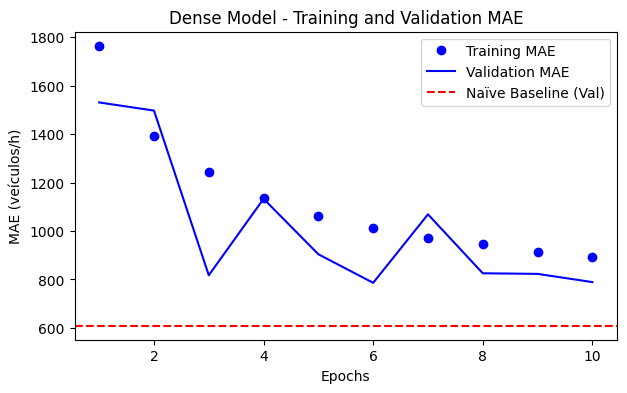

In [6]:
inputs = keras.Input(shape=(sequence_length, num_features))
x = layers.Flatten()(inputs)
x = layers.Dense(32, activation="relu")(x)
outputs = layers.Dense(1)(x)
model_dense = keras.Model(inputs, outputs)

model_dense.compile(optimizer="rmsprop", loss="mse", metrics=["mae"])
callbacks = [keras.callbacks.ModelCheckpoint("traffic_dense.keras", save_best_only=True)]

history_dense = model_dense.fit(
    train_dataset,
    epochs=10,
    validation_data=val_dataset,
    callbacks=callbacks
)

model_dense = keras.models.load_model("traffic_dense.keras")
dense_test_mae = model_dense.evaluate(test_dataset)[1] * std[0]
print(f"Dense Test MAE: {dense_test_mae:.2f}")
plot_history(history_dense, "Dense Model - Training and Validation MAE")

Epoch 1/10
79/79 ━━━━━━━━━━━━━━━━━━━━ 6s 69ms/step - loss: 0.9607 - mae: 0.8574 - val_loss: 0.7617 - val_mae: 0.7557
Epoch 2/10
79/79 ━━━━━━━━━━━━━━━━━━━━ 7s 80ms/step - loss: 0.8802 - mae: 0.8045 - val_loss: 0.6513 - val_mae: 0.6606
Epoch 3/10
79/79 ━━━━━━━━━━━━━━━━━━━━ 6s 67ms/step - loss: 0.8329 - mae: 0.7686 - val_loss: 0.5873 - val_mae: 0.6240
Epoch 4/10
79/79 ━━━━━━━━━━━━━━━━━━━━ 7s 81ms/step - loss: 0.8098 - mae: 0.7529 - val_loss: 0.5624 - val_mae: 0.6313
Epoch 5/10
79/79 ━━━━━━━━━━━━━━━━━━━━ 10s 77ms/step - loss: 0.7868 - mae: 0.7398 - val_loss: 0.5448 - val_mae: 0.5991
Epoch 6/10
79/79 ━━━━━━━━━━━━━━━━━━━━ 6s 67ms/step - loss: 0.7628 - mae: 0.7251 - val_loss: 0.5129 - val_mae: 0.5940
Epoch 7/10
79/79 ━━━━━━━━━━━━━━━━━━━━ 7s 80ms/step - loss: 0.7518 - mae: 0.7164 - val_loss: 0.5497 - val_mae: 0.5968
Epoch 8/10
79/79 ━━━━━━━━━━━━━━━━━━━━ 5s 67ms/step - loss: 0.7338 - mae: 0.7062 - val_loss: 0.4937 - val_mae: 0.5673
Epoch 9/10
79/79 ━━━━━━━━━━━━━━━━━━━━ 6s 78ms/step - loss: 0.72

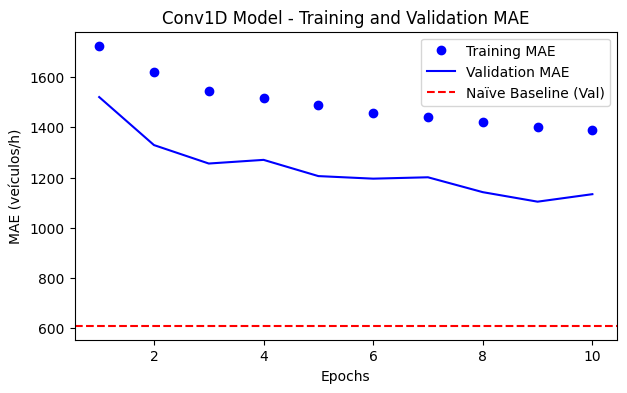

In [7]:
inputs = keras.Input(shape=(sequence_length, num_features))
x = layers.Conv1D(16, 24, activation="relu")(inputs)
x = layers.MaxPooling1D(2)(x)
x = layers.Conv1D(16, 12, activation="relu")(x)
x = layers.MaxPooling1D(2)(x)
x = layers.Conv1D(16, 6, activation="relu")(x)
x = layers.GlobalAveragePooling1D()(x)
outputs = layers.Dense(1)(x)
model_conv = keras.Model(inputs, outputs)

model_conv.compile(optimizer="rmsprop", loss="mse", metrics=["mae"])
callbacks = [keras.callbacks.ModelCheckpoint("traffic_conv.keras", save_best_only=True)]

history_conv = model_conv.fit(
    train_dataset,
    epochs=10,
    validation_data=val_dataset,
    callbacks=callbacks
)

model_conv = keras.models.load_model("traffic_conv.keras")
conv_test_mae = model_conv.evaluate(test_dataset)[1]* std[0]
print(f"Conv1D Test MAE: {conv_test_mae:.2f}")
plot_history(history_conv, "Conv1D Model - Training and Validation MAE")

Epoch 1/25
79/79 ━━━━━━━━━━━━━━━━━━━━ 32s 376ms/step - loss: 0.5865 - mae: 0.5865 - val_loss: 0.3161 - val_mae: 0.3161
Epoch 2/25
79/79 ━━━━━━━━━━━━━━━━━━━━ 30s 380ms/step - loss: 0.5186 - mae: 0.5186 - val_loss: 0.2653 - val_mae: 0.2653
Epoch 3/25
79/79 ━━━━━━━━━━━━━━━━━━━━ 30s 375ms/step - loss: 0.4951 - mae: 0.4951 - val_loss: 0.2363 - val_mae: 0.2363
Epoch 4/25
79/79 ━━━━━━━━━━━━━━━━━━━━ 31s 383ms/step - loss: 0.4845 - mae: 0.4845 - val_loss: 0.2415 - val_mae: 0.2415
Epoch 5/25
79/79 ━━━━━━━━━━━━━━━━━━━━ 31s 390ms/step - loss: 0.4778 - mae: 0.4778 - val_loss: 0.2244 - val_mae: 0.2244
Epoch 6/25
79/79 ━━━━━━━━━━━━━━━━━━━━ 36s 452ms/step - loss: 0.4712 - mae: 0.4712 - val_loss: 0.2266 - val_mae: 0.2266
Epoch 7/25
79/79 ━━━━━━━━━━━━━━━━━━━━ 30s 375ms/step - loss: 0.4648 - mae: 0.4648 - val_loss: 0.2259 - val_mae: 0.2259
Epoch 8/25
79/79 ━━━━━━━━━━━━━━━━━━━━ 30s 383ms/step - loss: 0.4582 - mae: 0.4582 - val_loss: 0.2181 - val_mae: 0.2181
Epoch 9/25
79/79 ━━━━━━━━━━━━━━━━━━━━ 30s 375ms/

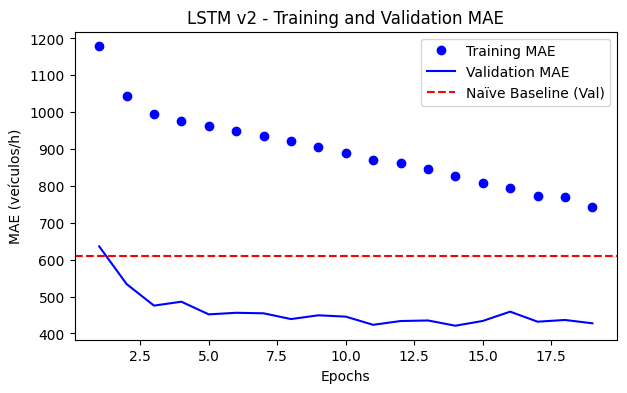

In [8]:
inputs = keras.Input(shape=(sequence_length, num_features))
x = layers.LSTM(64, return_sequences=True)(inputs)
x = layers.LSTM(32)(x)
x = layers.Dropout(0.1)(x)
outputs = layers.Dense(1)(x)
model_lstm = keras.Model(inputs, outputs)

model_lstm.compile(optimizer="adam", loss="mae", metrics=["mae"])

callbacks = [
    keras.callbacks.ModelCheckpoint("traffic_lstm_v2.keras", save_best_only=True),
    keras.callbacks.EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True)
]

history_lstm = model_lstm.fit(
    train_dataset,
    epochs=25,
    validation_data=val_dataset,
    callbacks=callbacks
)

model_lstm = keras.models.load_model("traffic_lstm_v2.keras")
lstm_test_mae = model_lstm.evaluate(test_dataset)[1] * std[0]
print(f"LSTM v2 Test MAE: {lstm_test_mae:.2f}")
plot_history(history_lstm, "LSTM v2 - Training and Validation MAE")

Epoch 1/15
79/79 ━━━━━━━━━━━━━━━━━━━━ 16s 175ms/step - loss: 0.6752 - mae: 0.6500 - val_loss: 0.2599 - val_mae: 0.3956
Epoch 2/15
79/79 ━━━━━━━━━━━━━━━━━━━━ 13s 168ms/step - loss: 0.5789 - mae: 0.5769 - val_loss: 0.2241 - val_mae: 0.3611
Epoch 3/15
79/79 ━━━━━━━━━━━━━━━━━━━━ 20s 168ms/step - loss: 0.5527 - mae: 0.5590 - val_loss: 0.2131 - val_mae: 0.3493
Epoch 4/15
79/79 ━━━━━━━━━━━━━━━━━━━━ 20s 166ms/step - loss: 0.5357 - mae: 0.5468 - val_loss: 0.1876 - val_mae: 0.3134
Epoch 5/15
79/79 ━━━━━━━━━━━━━━━━━━━━ 13s 164ms/step - loss: 0.5203 - mae: 0.5374 - val_loss: 0.1931 - val_mae: 0.3234
Epoch 6/15
79/79 ━━━━━━━━━━━━━━━━━━━━ 20s 164ms/step - loss: 0.5063 - mae: 0.5280 - val_loss: 0.1747 - val_mae: 0.3007
Epoch 7/15
79/79 ━━━━━━━━━━━━━━━━━━━━ 21s 167ms/step - loss: 0.4889 - mae: 0.5183 - val_loss: 0.1641 - val_mae: 0.2803
Epoch 8/15
79/79 ━━━━━━━━━━━━━━━━━━━━ 13s 164ms/step - loss: 0.4670 - mae: 0.5043 - val_loss: 0.1563 - val_mae: 0.2752
Epoch 9/15
79/79 ━━━━━━━━━━━━━━━━━━━━ 13s 165ms/

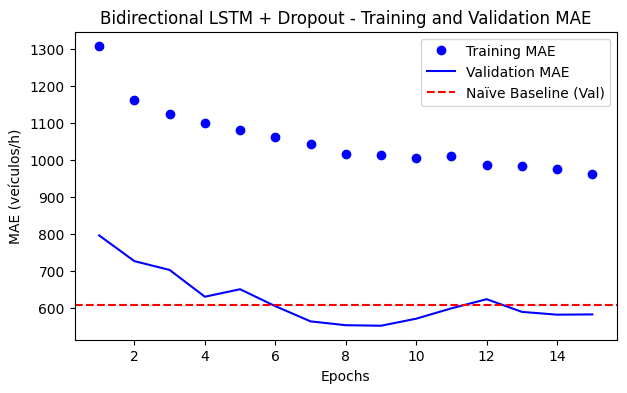

In [9]:
inputs = keras.Input(shape=(sequence_length, num_features))
x = layers.Bidirectional(layers.LSTM(32))(inputs)
x = layers.Dropout(0.3)(x)
outputs = layers.Dense(1)(x)
model_bilstm = keras.Model(inputs, outputs)

model_bilstm.compile(optimizer="adam", loss="mse", metrics=["mae"])
callbacks = [keras.callbacks.ModelCheckpoint("traffic_bilstm.keras", save_best_only=True)]

history_bilstm = model_bilstm.fit(
    train_dataset,
    epochs=15,
    validation_data=val_dataset,
    callbacks=callbacks
)

model_bilstm = keras.models.load_model("traffic_bilstm.keras")
bilstm_test_mae = model_bilstm.evaluate(test_dataset)[1]* std[0]
print(f"Bidirectional LSTM Test MAE: {bilstm_test_mae:.2f}")
plot_history(history_bilstm, "Bidirectional LSTM + Dropout - Training and Validation MAE")

In [10]:
# Tabela comparativa final dos modelos no conjunto de teste
resultados = pd.DataFrame({
    'Modelo': [
        'Baseline Naïve',
        'Dense',
        'Conv1D',
        'LSTM v2 (64→32 + Dropout)',
        'Bi-LSTM + Dropout'
    ],
    'Test MAE (veículos/h)': [
        naive_test_mae,
        dense_test_mae,
        conv_test_mae,
        lstm_test_mae,
        bilstm_test_mae
    ]
}).sort_values('Test MAE (veículos/h)')

print(resultados.to_string(index=False))

                   Modelo  Test MAE (veículos/h)
LSTM v2 (64→32 + Dropout)             356.566193
        Bi-LSTM + Dropout             505.273590
           Baseline Naïve             590.636292
                    Dense             756.908508
                   Conv1D            1133.005127
